In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Create Dataframe

In [ ]:
df = pd.DataFrame({
    'Maths':[6,8,6,14.5,14,11,5.5,13,9],
    'Sciences':[6,8,7,14.5,14,10,7,12.5,9.5],
    'Francais':[5,8,11,15.5,12,5.5,14,8.5,12.5],
    'Latin':[5.5,8,9.5,15,12,7,11.5,9.5,12],
    'Musique':[8,9,11,8,10,13,10,12,18]
})
df

,Maths,Sciences,Francais,Latin,Musique
0,6.0,6.0,5.0,5.5,8
1,8.0,8.0,8.0,8.0,9
2,6.0,7.0,11.0,9.5,11
3,14.5,14.5,15.5,15.0,8
4,14.0,14.0,12.0,12.0,10
5,11.0,10.0,5.5,7.0,13
6,5.5,7.0,14.0,11.5,10
7,13.0,12.5,8.5,9.5,12
8,9.0,9.5,12.5,12.0,18


In [ ]:
# Rename the row indices with student names
df.index = ['Jean', 'Jacques', 'Aline', 'Emeline','Antoine', 'Jules','Chloé','Jeanne','Béatrice']
df

,Maths,Sciences,Francais,Latin,Musique
Jean,6.0,6.0,5.0,5.5,8
Jacques,8.0,8.0,8.0,8.0,9
Aline,6.0,7.0,11.0,9.5,11
Emeline,14.5,14.5,15.5,15.0,8
Antoine,14.0,14.0,12.0,12.0,10
Jules,11.0,10.0,5.5,7.0,13
Chloé,5.5,7.0,14.0,11.5,10
Jeanne,13.0,12.5,8.5,9.5,12
Béatrice,9.0,9.5,12.5,12.0,18


## Covariance Matrix


In [ ]:
cov_matrix = df.cov()
print(cov_matrix)

              Maths   Sciences   Francais     Latin  Musique
Maths     12.812500  11.156250   2.989583   5.15625   0.1250
Sciences  11.156250  10.062500   4.635417   5.90625   0.0625
Francais   2.989583   4.635417  13.569444  10.34375   0.4375
Latin      5.156250   5.906250  10.343750   8.62500   0.8125
Musique    0.125000   0.062500   0.437500   0.81250   9.7500


# Normalization of the data


In [ ]:
X = df.values
print(X)
print(type(X))

[[ 6.   6.   5.   5.5  8. ]
 [ 8.   8.   8.   8.   9. ]
 [ 6.   7.  11.   9.5 11. ]
 [14.5 14.5 15.5 15.   8. ]
 [14.  14.  12.  12.  10. ]
 [11.  10.   5.5  7.  13. ]
 [ 5.5  7.  14.  11.5 10. ]
 [13.  12.5  8.5  9.5 12. ]
 [ 9.   9.5 12.5 12.  18. ]]
<class 'numpy.ndarray'>


In [ ]:
# Import
from sklearn.preprocessing import StandardScaler

In [ ]:
# Centering and Standardizing Data
Z = StandardScaler().fit_transform(X)
print(Z)

[[-1.08650256 -1.28173989 -1.50366322 -1.62520902 -1.01904933]
 [-0.4938648  -0.61300603 -0.63985669 -0.72231512 -0.67936622]
 [-1.08650256 -0.94737296  0.22394984 -0.18057878  0.        ]
 [ 1.43220792  1.560379    1.51965963  1.8057878  -1.01904933]
 [ 1.28404848  1.39319553  0.51188535  0.72231512 -0.33968311]
 [ 0.39509184  0.05572782 -1.35969546 -1.08347268  0.67936622]
 [-1.234662   -0.94737296  1.08775637  0.54173634 -0.33968311]
 [ 0.9877296   0.89164514 -0.49588893 -0.18057878  0.33968311]
 [-0.19754592 -0.11145564  0.65585311  0.72231512  2.37778177]]


In [ ]:
# Check that the means are 0 and the standard deviations are 1.
print(np.mean(Z,axis=0))
print(np.std(Z,axis=0))

[ 1.81953218e-16 -2.20502629e-16  2.34380416e-16 -1.23358114e-17
  4.93432455e-17]
[1. 1. 1. 1. 1.]


##Covariance matrix (correlation matrix since Z is a standardized variable )

In [ ]:
cov_matrix = np.cov(Z, rowvar=False)  # rowvar=False car les colonnes = variables
print('The correlation/covariance matrix (dividing by n-1 = 9-1 = 8)')
print(cov_matrix)

The correlation/covariance matrix (dividing by n-1 = 9-1 = 8)
[[1.125      1.10535269 0.25507342 0.55181055 0.01258181]
 [1.10535269 1.125      0.44627989 0.71323369 0.00709867]
 [0.25507342 0.44627989 1.125      1.07564745 0.04279049]
 [0.55181055 0.71323369 1.07564745 1.125      0.09967679]
 [0.01258181 0.00709867 0.04279049 0.09967679 1.125     ]]


# PCA


Notations:
*   $NI$: Cloud of individuals.

Key points of PCA:
*   PCA searches for the best synthesis space for optimal $NI$ visualisation.

Viewpoint quality:
*   Reproduce the $NI$'s shape.
*   Optimize representation of diversity and variability.
*   Maintain distances between individuals


Quantifying viewpoint quality:
*   Use Inertia.
*   Inertia = variance generalized to multiple dimensions.


Inertia
- Inertia refers to the total variation in the data.  
- It measures the total squared distance between individuals and the mean center (cloud center).  
- Inertia equals the sum of squared Euclidean distances from each point to the data mean.  
- This value represents the total variance of the dataset.  

$$Inertia (Before PCA) = \sum_{i=1}^{n} d(I_{i},O) $$

With:
- $I_{i}$: individual $i$.
- $O$: is the mean (center) of the data.
- $d(I_{i},O)$: distance between individual $i$ and $O$.

Example of $d(I_{i},O)$:
- Euclidean distance:
$$ d(I_{i},O) = ||I_{i} - O||^{2} $$



*   <font color="cyan">
     Inertia before PCA refers to the total squared distances from each individual to the center of the data (the mean), which is a measure of the total variance in the dataset.
</font>
*   <font color="cyan">
 After PCA, the inertia is redistributed along the principal components, and the explained inertia corresponds to the variance captured by each principal component.
</font>







In [ ]:
# Import
from sklearn.decomposition import PCA

# Instanciation of PCA
pca = PCA()
# The PCA is performed, and the factor scores are retrieved in the matrix 'coord'.
coord = pca.fit_transform(Z)
print(coord)
# Number of principal components
n = (pca.n_components_)
print(n)

[[-2.78571626 -0.6764554  -0.73680069  0.04824298 -0.0332307 ]
 [-1.26249031 -0.33033839 -0.55495038  0.03576028  0.01091186]
 [-1.01674674  1.01982862 -0.28808844 -0.06237732  0.00743856]
 [ 3.12214541 -0.16584307 -1.14426837  0.10012136  0.00532702]
 [ 1.95510007 -0.78790499 -0.18921203 -0.09873943 -0.01278293]
 [-0.9477522  -1.20140468  1.14011052  0.01857612  0.04027278]
 [-0.32496763  1.75473914 -0.90951345 -0.04309011  0.01406045]
 [ 0.63734131 -1.12985744  0.69185868 -0.05383744 -0.01383015]
 [ 0.62308636  1.51723621  1.99086415  0.05534356 -0.01816687]]
5


In [ ]:
# Retrieve the eigenvalues / variance / inertia.
# The variance is estimated with n-1 degrees of freedom.
variance = pca.explained_variance_

# An adjustment is necessary to obtain the variance with n degrees of freedom.
eigval = variance*(len(Z)-1)/len(Z)
print('Eigenvalues (Variances of principal components) are :')
for index, lambda_k in enumerate(eigval):
  print(f'Variance of principal component PC{index+1}: Lambda_k = {lambda_k}')


Eigenvalues (Variances of principal components) are :
Variance of principal component PC1: Lambda_k = 2.861817528250899
Variance of principal component PC2: Lambda_k = 1.1506811283043108
Variance of principal component PC3: Lambda_k = 0.9831407382989998
Variance of principal component PC4: Lambda_k = 0.003937120525440214
Variance of principal component PC5: Lambda_k = 0.0004234846203498364


In [ ]:

print(round(np.sum(eigval,axis=0)))

5


In [ ]:
# Eigenvalue representation ratio or the percentage of inertia explained by each axis
np.set_printoptions(suppress=True)
print(pca.explained_variance_ratio_*100)

[57.23635057 23.01362257 19.66281477  0.07874241  0.00846969]


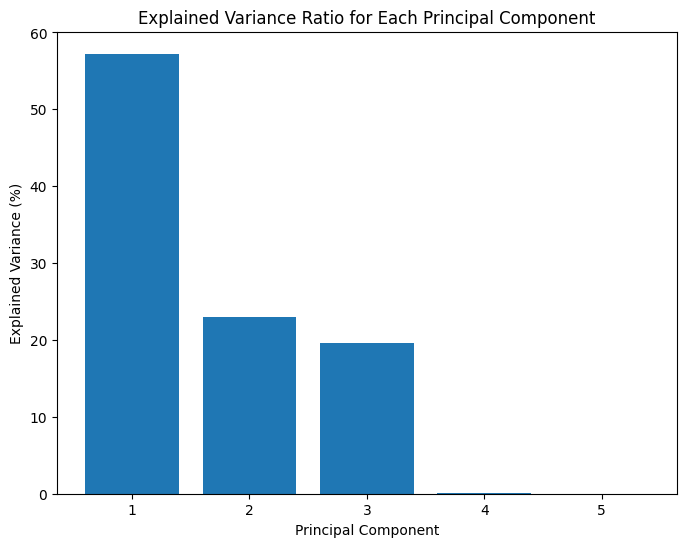

In [ ]:
# Plotting the histogram
plt.figure(figsize=(8, 6))
plt.bar(range(1, len(pca.explained_variance_ratio_*100) + 1), pca.explained_variance_ratio_ * 100)
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.title('Explained Variance Ratio for Each Principal Component')
plt.show()

# Representation of individuals

## Coordinates of individuals

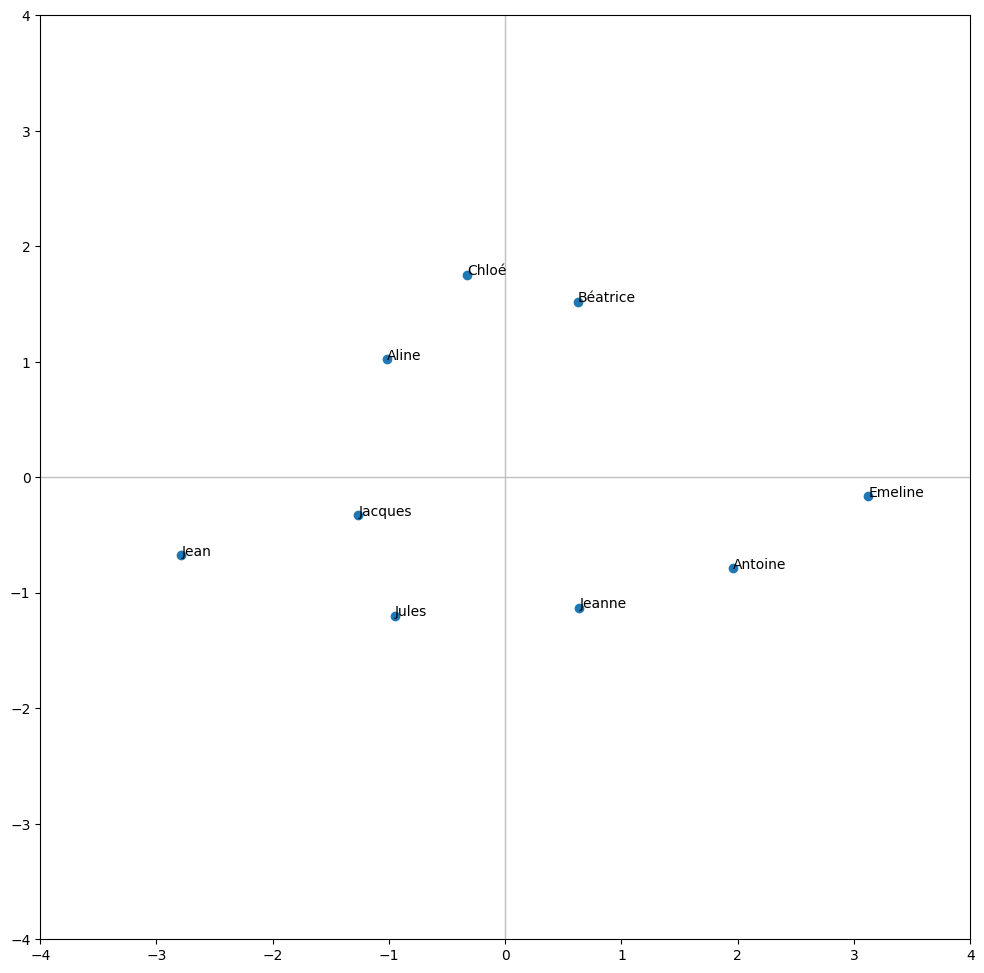

In [ ]:
# Creation of the graph
fig, ax = plt.subplots(figsize=(12,12))
ax.set_xlim(-4,4)
ax.set_ylim(-4,4)

# Placement of the points
plt.scatter(coord[:,0],coord[:,1])

# Placement of the observation labels
for i in range(len(Z)):
     plt.annotate(df.index[i],(coord[i,0],coord[i,1]))

# Addition of axes
plt.plot([-4,4],[0,0],color='silver',linestyle='-',linewidth=1)
plt.plot([0,0],[-4,4],color='silver',linestyle='-',linewidth=1)

# Display
plt.show()

## Quality of presentation


The quality of representation of individual $i$ on axis $j$ is calculated as follows:


$$COS_{ij}^{2} = \frac{F_{ij}^{2}}{d_{i}^{2}}$$


where:
*    $F_{ij}$: the coordinates of individual $i$ on axis $j$ in the factorial plane (which we obtained from the variable `coord`).
*   $d_{i}^{2}$: the square of the distance from individual $i$ to the origin (calculated below).


<font color = "cyan"> Interpretation of the quality </font>

*   $COS^{2}$: tells how well an individual is represented on the principal component (axis).
*   A high $COS^{2}$ value indicates that the individual is well represented on the axis. This means that the individual’s information or variance is strongly captured by this axis.
*   A low $COS^{2}$ value means that the individual is poorly represented by the axis. The variance or information about this individual is not well captured by this axis.

In [ ]:
# Compute the distance of each individual to the origin
di2 = np.sum(coord**2,axis=1)
print(pd.DataFrame({'ID':df.index,'d_i':di2}))

         ID        d_i
0      Jean   8.764114
1   Jacques   2.012373
2     Aline   2.160766
3   Emeline  11.094699
4   Antoine   4.488925
5     Jules   3.643426
6     Chloé   4.013983
7    Jeanne   2.164540
8  Béatrice   6.657175


In [ ]:
# Quality of Representation of Individuals - COS2
COS2 = coord**2
# We calculate the quality of representation of individuals on each of the 5 axes.
for j in range(5):
     COS2[:,j] = COS2[:,j]/di2

# We display it for the first two principal axes
print(pd.DataFrame({'id':df.index,'COS^2_1':COS2[:,0],'COS^2_2':COS2[:,1],'COS2^2_3':COS2[:,2]}))

         id   COS^2_1   COS^2_2  COS2^2_3
0      Jean  0.885453  0.052212  0.061943
1   Jacques  0.792041  0.054226  0.153038
2     Aline  0.478429  0.481334  0.038410
3   Emeline  0.878599  0.002479  0.118016
4   Antoine  0.851522  0.138295  0.007975
5     Jules  0.246536  0.396158  0.356766
6     Chloé  0.026309  0.767096  0.206083
7    Jeanne  0.187663  0.589769  0.221141
8  Béatrice  0.058319  0.345793  0.595379


In [ ]:
# Let's verify that each individual is represented 100% when considering all the axes.
# Thus, the sum of the COS2 values across all axes for each individual should equal 1
print(np.sum(COS2,axis=1))

[1. 1. 1. 1. 1. 1. 1. 1. 1.]


# Representation of the variables

<font color="cyan"> Principal Components as Linear Combinations </font>

Each principal component is a linear combination of the original variables. The coefficients of this linear combination are the elements of the eigenvectors (also called loadings).

$$ PC_{j}=\sum_{k=1}^{K}components\__{jk}⋅X_{k}$$

Where:


*   $PC_{j}$​ is the $j$-th principal component.
*   $components\__{jk}​$ is the loading (or weight) of the $k$-th variable on the $j$-th principal component.
*   $X_{k}$​ is the $k$-th original variable.
*    $K$ is the total number of variables.

Interpretation of $components\__{jk}​$


*   $components\__{jk}​$ measures the contribution of the $k$-th variable to the $j$-th principal component.
*   The sign of $components\__{jk}​$​ indicates the direction of the relationship:
*    Positive: $X_{k}$​ and $PC_{j}$​ increase together.
*    Negative: $X_{k}​$ and $PC_{j}$​ move in opposite directions.

The magnitude of $components\__{jk}​$ reflects the strength of the contribution.  








In [ ]:
print('The eigenvector matrix (line j: eigenvector of principal component j + 1)')
X_names = df.keys()
for j in range(len(pca.components_)):
  print(f'CP_{j+1}, eigenvector_{j+1}:{pca.components_[j]}')


The eigenvector matrix (line j: eigenvector of principal component j + 1)
CP_1, eigenvector_1:[0.47639106 0.53024454 0.44812425 0.53807342 0.03941992]
CP_2, eigenvector_2:[-0.53263677 -0.40159625  0.56963554  0.37055187  0.305328  ]
CP_3, eigenvector_3:[ 0.15475344  0.09364365 -0.22763607 -0.10934894  0.95052978]
CP_4, eigenvector_4:[ 0.30298298 -0.51679947 -0.47749743  0.64155887 -0.03896199]
CP_5, eigenvector_5:[ 0.61123017 -0.53076393  0.44144992 -0.38679883  0.01399912]


$CP_{1}$ = 0.47639106*$Maths_{cr}$ + 0.53024454*$Science_{cr}$ + 0.44812424*$Français_{cr}$ + 0.53807342*$Latin_{cr}$ + 003941992*$Musique_{cr}$

$CP_{2}$ = -0.53263677*$Maths_{cr}$ -0.40159625*$Science_{cr}$ + 0.56963554*$Français_{cr}$ + 0.37055187*$Latin_{cr}$ + 0.305328*$Musique_{cr}$

$CP_{3}$ = 0.15475344*$Maths_{cr}$ + 0.09364365*$Science_{cr}$ -0.22763607*$Français_{cr}$ -0.10934894*$Latin_{cr}$ + 0.95052978*$Musique_{cr}$

$CP_{4}$ = 0.30298298*$Maths_{cr}$ -0.51679947*$Science_{cr}$ -0.47749743*$Français_{cr}$ + 0.64155887*$Latin_{cr}$ -0.03896199*$Musique_{cr}$

$CP_{5}$ = 0.61123017*$Maths_{cr}$ -0.53076393*$Science_{cr}$ + 0.44144992*$Français_{cr}$ -0.38679883*$Latin_{cr}$ + 0.01399912*$Musique_{cr}$

     
     

## Correlation between principal components and variables
The correlation between $PC_{j}$​ and $X_{k}$​ can be derived from $components\__{kj}​$​. It adjusts the loading by the variance of the $k$-th variable and the variance explained by $PC_{j}$​:
$$Correlation(X_{k},PC_{j})=\frac{components\__{jk}​⋅\lambda_{j}}{std(X_{k})}$$

Where:
*   $\lambda_{j}$: is the eigenvalue associated with $PC_{j}$, representing the variance it explains.

<font color = "cyan"> pca.components_.T </font>

In the following cell, pca.components_.T is represented as:

$$
pca.components\_.T =
\begin{bmatrix}
pca.components\_.T_{11} & pca.components\_.T_{12} & ... & pca.components\_.T_{1J} \\
pca.components\_.T_{21} & pca.components\_.T_{22} & ... & pca.components\_.T_{2J} \\
... & ... & ... & p... \\
pca.components\_.T_{K1} & pca.components\_.T_{K2} & ... & pca.components\_.T_{KJ} \\
\end{bmatrix}
$$

With:
*    $J$: the total number of principal components.




In [ ]:
# We need the eigenvectors for the analysis of the variables.
# We retrieve the components_ field from the PCA object.
# acp.components_ returns the matrix of eigenvectors with:
#                                                        - rows as principal components
#                                                        - columns as variables
# Transpose acp.components_ to get eigenvectors (variables x principal components).
vp_mat=pca.components_.T
vp_mat

array([[ 0.47639106, -0.53263677,  0.15475344,  0.30298298,  0.61123017],
       [ 0.53024454, -0.40159625,  0.09364365, -0.51679947, -0.53076393],
       [ 0.44812425,  0.56963554, -0.22763607, -0.47749743,  0.44144992],
       [ 0.53807342,  0.37055187, -0.10934894,  0.64155887, -0.38679883],
       [ 0.03941992,  0.305328  ,  0.95052978, -0.03896199,  0.01399912]])

In [ ]:
# We calculate the square root of the eigenvalues.
sqrt_eigval = np.sqrt(eigval)

In [ ]:
# Correlation of variables with the axes.
corvar = np.zeros((5,5))
for j in range(5):
     corvar[:,j] = vp_mat[:,j] * sqrt_eigval[j]

# Display the matrix of correlations (variables x factors).
print(corvar)

# We display the correlations for the first two axes.
print(pd.DataFrame({'id':df.columns,'COR_1 - CP1':corvar[:,0],'COR_2 - CP2':corvar[:,1],'COR_3 - CP3':corvar[:,2]}))

[[ 0.80590635 -0.57135843  0.15344338  0.01901111  0.01257835]
 [ 0.89700978 -0.43079152  0.09285091 -0.03242735 -0.01092245]
 [ 0.75808764  0.61104694 -0.22570903 -0.02996128  0.00908448]
 [ 0.91025382  0.39749027 -0.10842325  0.04025556 -0.00795983]
 [ 0.06668631  0.32752476  0.94248311 -0.00244473  0.00028808]]
         id  COR_1 - CP1  COR_2 - CP2  COR_3 - CP3
0     Maths     0.805906    -0.571358     0.153443
1  Sciences     0.897010    -0.430792     0.092851
2  Francais     0.758088     0.611047    -0.225709
3     Latin     0.910254     0.397490    -0.108423
4   Musique     0.066686     0.327525     0.942483


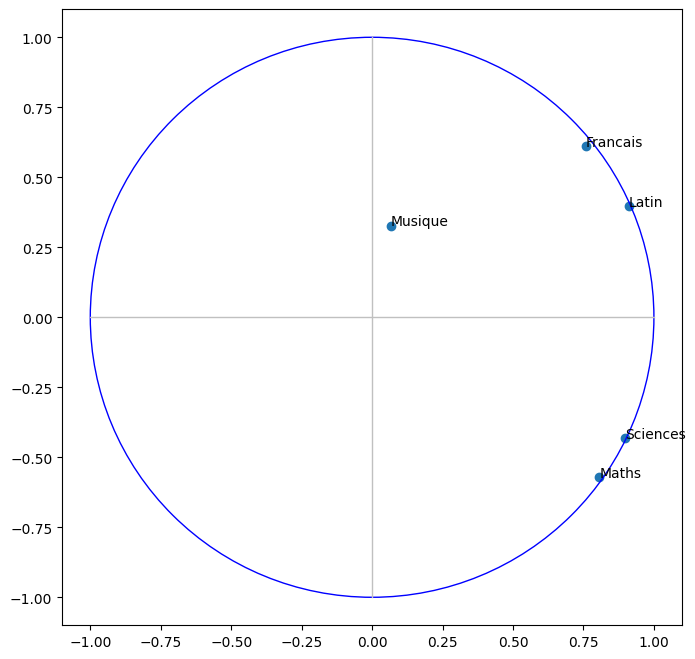

In [ ]:
# Correlation circle for the first two axes.
fig, axes = plt.subplots(figsize=(8,8))

# Points
plt.scatter(corvar[:,0],corvar[:,1])

# Display the labels (variable names).
for k in range(5):
     plt.annotate(df.columns[k],(corvar[k,0],corvar[k,1]))

# Add the axes.
plt.plot([-1,1],[0,0],color='silver',linestyle='-',linewidth=1)
plt.plot([0,0],[-1,1],color='silver',linestyle='-',linewidth=1)

# Add the circle.
cercle = plt.Circle((0,0),1,color='blue',fill=False)
axes.add_artist(cercle)

# Display
plt.show()

### Interpretation of correlation circle
1. Strong correlation between Maths and Science.
2. Strong correlation between Français and Latin.
3. CP1: General academic (Maths, Science, Français, Latin).
4. CP2: Literature (Français, Latin) vs. scientific orientation (Maths, Sciene).
5. CP3: Musique.